# Spatial density of objects in orbit, by category

Merges a TLE snapshot (file `tle_YYYYMMDD_YYYYMMDD.csv` written by `spacetrack_tle_snapshot.py`
in the folder set in `config.ini`, section `[tle_snapshot]`) with a SATCAT file
(`satcat_YYYYMMDD.csv` written by `spacetrack_satcat.py`, section `[satcat]`).

The TLEs give the current orbit of each object (perigee and apogee from the mean motion and the eccentricity),
SATCAT gives its category (`OBJECT_TYPE`). The spatial density is then computed against altitude,
for all objects and per category (satellites, debris, upper stages, unknown).

In [13]:
from pathlib import Path
import configparser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TLE_SNAPSHOT = "tle_20261107_20261108.csv"
SATCAT       = "satcat_20261107.csv"

# Folders read from config.ini (same file as spacetrack_tle_snapshot.py and spacetrack_satcat.py)
config = configparser.ConfigParser()
if not config.read("config.ini", encoding="utf-8"):
    raise FileNotFoundError("config.ini not found next to the notebook")
TLE_FILE    = Path(config["tle_snapshot"]["output_dir"]).expanduser() / TLE_SNAPSHOT
SATCAT_FILE = Path(config["satcat"]["output_dir"]).expanduser() / SATCAT
for f in (TLE_FILE, SATCAT_FILE):
    if not f.exists():
        raise FileNotFoundError(f"File not found: {f} (see output_dir in config.ini)")

MU       = 398_600.4418 # km³/s², Earth gravitational parameter
R_EARTH  = 6_378.137    # km, Earth equatorial radius (WGS84)
LEO_MAX  = 2000         # km, upper bound of the LEO plots
LEO_BIN  = 10           # km, bin width of the LEO plots
FULL_MAX = 40000        # km, upper bound of the full-range plot (GEO included)
FULL_BIN = 50           # km, bin width of the full-range plot

# Categories: display label and colour (fixed order)
TYPE_MAP = {
    "PAYLOAD":     ("Satellite",   "#2a78d6"),
    "DEBRIS":      ("Debris",      "#eb6834"),
    "ROCKET BODY": ("Upper Stage", "#1baf7a"),
    "UNKNOWN":     ("Unknown",     "#eda100"),
}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a",
    "xtick.color": "#3d3d3a", "ytick.color": "#3d3d3a",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e8e7e1", "axes.axisbelow": True,
    "font.size": 11,
})

## Read and merge the files

Orbital elements are read from the fixed columns of the TLE lines: epoch (line 1, columns 19-32),
eccentricity (line 2, columns 27-33) and mean motion (line 2, columns 53-63).
The semi-major axis comes from the mean motion, `a = (μ / n²)^(1/3)`, then
perigee and apogee altitudes are `a(1 ∓ e) - R_earth`.

In [14]:
def parse_tle(path: Path) -> pd.DataFrame:
    """Orbital elements of each TLE of the snapshot (one row per object)."""
    raw = pd.read_csv(path)
    l1, l2 = raw["line1"].str, raw["line2"].str
    n   = l2.slice(52, 63).astype(float) * 2 * np.pi / 86_400   # rad/s
    ecc = ("0." + l2.slice(26, 33).str.strip()).astype(float)
    sma = (MU / n ** 2) ** (1 / 3)
    yy  = l1.slice(18, 20).astype(int)
    epoch = (pd.to_datetime((np.where(yy < 57, 2000, 1900) + yy).astype(str), format="%Y")
             + pd.to_timedelta(l1.slice(20, 32).astype(float) - 1, unit="D"))
    return pd.DataFrame({"NORAD_CAT_ID": raw["norad_id"].astype(int), "TLE_NAME": raw["name"],
                         "EPOCH": epoch, "SMA": sma, "ECC": ecc, "INC": l2.slice(8, 16).astype(float),
                         "PERIGEE": sma * (1 - ecc) - R_EARTH, "APOGEE": sma * (1 + ecc) - R_EARTH})

tle = parse_tle(TLE_FILE)
satcat = pd.read_csv(SATCAT_FILE)
print(f"TLE snapshot: {TLE_FILE.name} — {len(tle):,} objects, "
      f"epochs {tle['EPOCH'].min():%Y-%m-%d} → {tle['EPOCH'].max():%Y-%m-%d}")
print(f"SATCAT      : {SATCAT_FILE.name} — {len(satcat):,} objects")

# SATCAT perigee/apogee are dropped: the TLE values are the current ones
population = tle.merge(satcat.drop(columns=["PERIGEE", "APOGEE"]), on="NORAD_CAT_ID",
                       how="left", indicator=True)
missing = population["_merge"] == "left_only"
print(f"{missing.sum():,} TLE objects not found in SATCAT (catalogued after the SATCAT file) → Unknown")
population["OBJECT_TYPE"] = population["OBJECT_TYPE"].fillna("UNKNOWN")
population = population.drop(columns="_merge")

decayed = population["DECAY"].notna()
invalid = (population["PERIGEE"] <= 0) | population["SMA"].isna() | (population["ECC"] >= 1)
print(f"{decayed.sum():,} objects marked as decayed in SATCAT, {invalid.sum():,} invalid orbits → removed")
in_orbit = population[~decayed & ~invalid].copy()
print(f"{len(in_orbit):,} objects in orbit")

TLE snapshot: tle_20261107_20261108.csv — 27,309 objects, epochs 2024-12-20 → 2026-11-08
SATCAT      : satcat_20261107.csv — 71,266 objects
145 TLE objects not found in SATCAT (catalogued after the SATCAT file) → Unknown
0 objects marked as decayed in SATCAT, 0 invalid orbits → removed
27,309 objects in orbit


In [15]:
by_type = in_orbit["OBJECT_TYPE"].value_counts().reindex(TYPE_MAP, fill_value=0)
display(pd.DataFrame({"Category": [TYPE_MAP[t][0] for t in by_type.index],
                      "Objects": by_type.values,
                      "%": (100 * by_type / by_type.sum()).round(1).values}))

,Category,Objects,%
0,Satellite,18456,67.6
1,Debris,6787,24.9
2,Upper Stage,1920,7.0
3,Unknown,146,0.5


## Spatial density vs altitude

Each object is spread over the altitude bins between its perigee and apogee, in proportion to the
time it spends in each bin on a Keplerian orbit (mean anomaly from Kepler's equation `M = E - e sin E`).
The spatial density of a bin is the number of objects in it divided by the volume of the spherical shell
(objects/km³).

In [16]:
def time_fraction_below(r, rp, ra):
    """Fraction of the orbital period spent below radius r (km), orbits given by rp/ra (km).
    r: (n_edges,), rp/ra: (n_obj, 1). Uses r = a(1 - e cos E) and M = E - e sin E."""
    a = (rp + ra) / 2
    e = (ra - rp) / (ra + rp)
    with np.errstate(divide="ignore", invalid="ignore"):
        E = np.arccos(np.clip((1 - r / a) / e, -1, 1))
        frac = (E - e * np.sin(E)) / np.pi
    return np.where(e < 1e-9, (r >= a).astype(float), frac)   # circular orbit: step at r = a

def density_profile(objects, h_max, h_bin, chunk=2000):
    """Mean number of objects and spatial density (objects/km³) per altitude bin."""
    edges = np.arange(0, h_max + h_bin, h_bin)
    r = R_EARTH + edges
    counts = np.zeros(len(edges) - 1)
    rp_all = R_EARTH + objects["PERIGEE"].to_numpy(float)
    ra_all = R_EARTH + objects["APOGEE"].to_numpy(float)
    for i in range(0, len(rp_all), chunk):   # chunks keep the (objects x bins) matrix small
        f = time_fraction_below(r, rp_all[i:i + chunk, None], ra_all[i:i + chunk, None])
        counts += np.diff(f, axis=1).sum(axis=0)
    volume = 4 / 3 * np.pi * (r[1:] ** 3 - r[:-1] ** 3)
    return pd.DataFrame({"altitude": (edges[:-1] + edges[1:]) / 2,
                         "objects": counts, "density": counts / volume})

# Orbital regimes from perigee/apogee (GEO: ±200 km around 35,786 km)
regimes = ["LEO", "MEO", "GEO", "Beyond GEO", "Eccentric (HEO, GTO…)"]
p, a = in_orbit["PERIGEE"], in_orbit["APOGEE"]
in_orbit["REGIME"] = np.select([a < 2000,
                                (p >= 2000) & (a < 35586),
                                (p >= 35586) & (a <= 35986),
                                p > 35986],
                               regimes[:4], regimes[4])

groups = {"All objects": in_orbit,
          **{TYPE_MAP[t][0]: in_orbit[in_orbit["OBJECT_TYPE"] == t] for t in TYPE_MAP}}
groups = {name: g for name, g in groups.items() if len(g)}
leo  = {name: density_profile(g, LEO_MAX, LEO_BIN) for name, g in groups.items()}
full = {name: density_profile(g, FULL_MAX, FULL_BIN) for name, g in groups.items()}
categories = [t for t in TYPE_MAP if TYPE_MAP[t][0] in groups]   # categories with objects

summary = pd.DataFrame({
    name: {"Objects": len(g),
           "LEO peak (km)": int(leo[name].loc[leo[name]["density"].idxmax(), "altitude"]),
           "LEO peak density (obj/km³)": f"{leo[name]['density'].max():.2e}",
           **g["REGIME"].value_counts().reindex(regimes, fill_value=0).to_dict()}
    for name, g in groups.items()}).T
display(summary)

,Objects,LEO peak (km),LEO peak density (obj/km³),LEO,MEO,GEO,Beyond GEO,"Eccentric (HEO, GTO…)"
All objects,27309,465,8.06e-07,23891,580,784,482,1572
Satellite,18456,465,8.03e-07,16789,306,705,406,250
Debris,6787,795,2.79e-08,5983,89,13,15,687
Upper Stage,1920,985,5.02e-09,979,185,66,61,629
Unknown,146,795,2.14e-09,140,0,0,0,6


### All objects — LEO

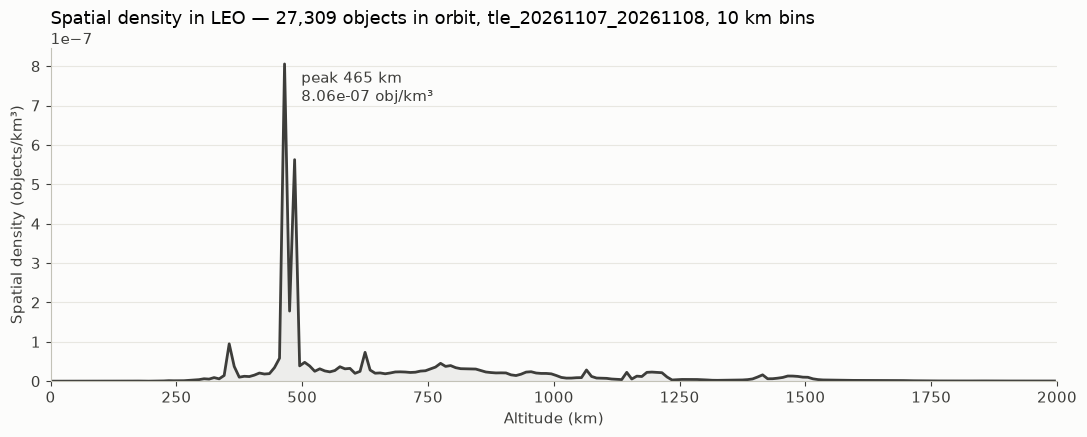

In [17]:
prof = leo["All objects"]
peak = prof.loc[prof["density"].idxmax()]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(prof["altitude"], prof["density"], color="#3d3d3a", linewidth=2)
ax.fill_between(prof["altitude"], prof["density"], color="#3d3d3a", alpha=0.08, linewidth=0)
ax.annotate(f"peak {peak['altitude']:.0f} km\n{peak['density']:.2e} obj/km³",
            xy=(peak["altitude"], peak["density"]), xytext=(12, -4), textcoords="offset points",
            va="top", color="#3d3d3a")
ax.set_xlim(0, LEO_MAX)
ax.set_ylim(bottom=0)
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Spatial density (objects/km³)")
ax.set_title(f"Spatial density in LEO — {len(in_orbit):,} objects in orbit, "
             f"{TLE_FILE.stem}, {LEO_BIN} km bins", loc="left")
fig.tight_layout()
plt.show()

### By category — LEO

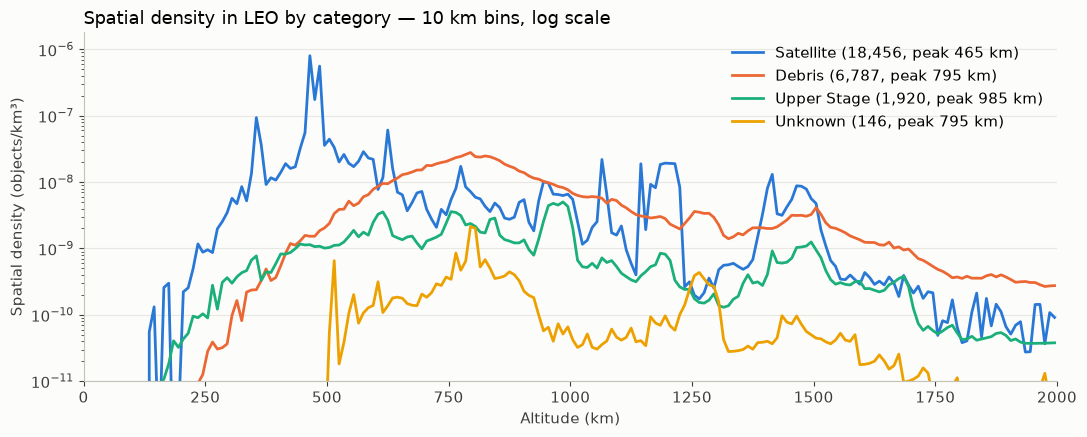

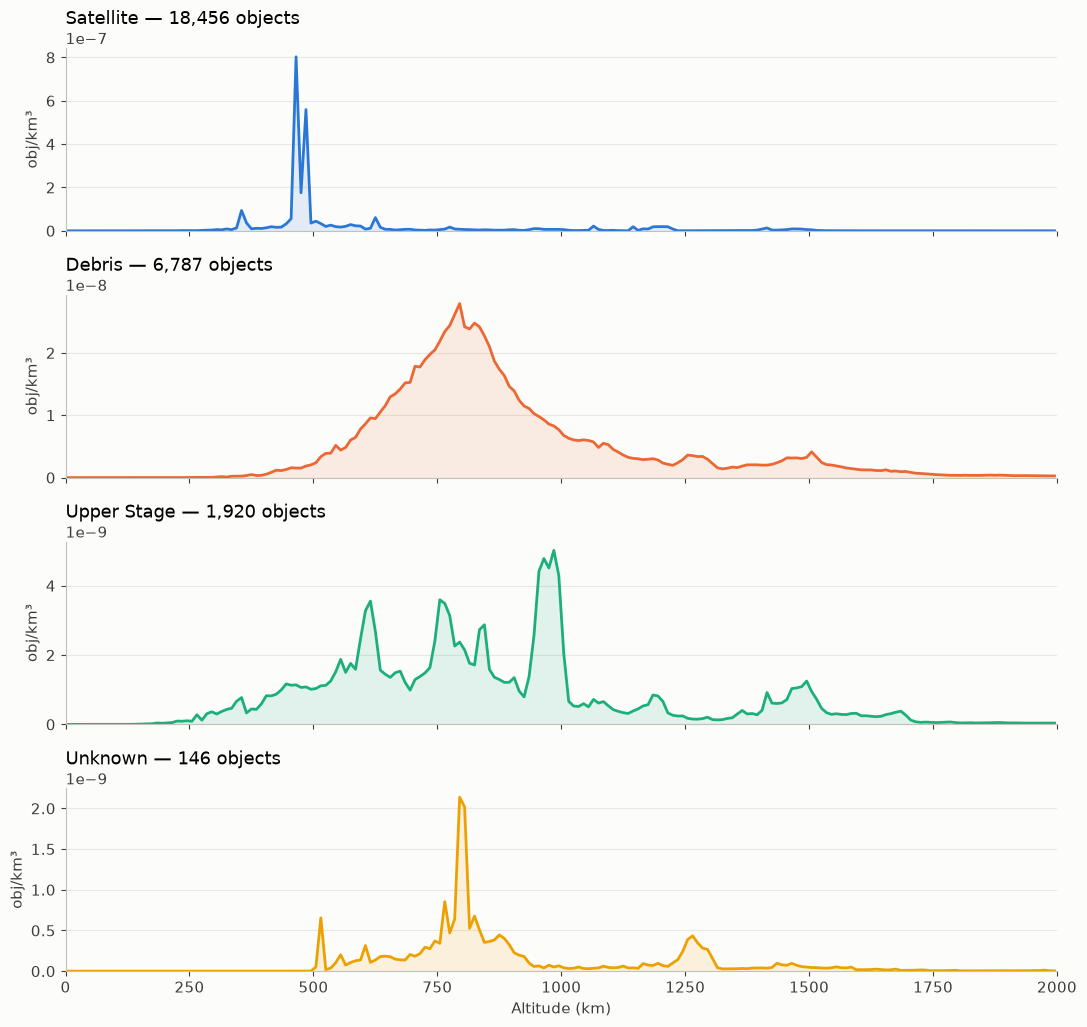

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for obj_type in categories:
    label, color = TYPE_MAP[obj_type]
    prof = leo[label]
    peak = prof.loc[prof["density"].idxmax()]
    ax.plot(prof["altitude"], prof["density"], color=color, linewidth=2,
            label=f"{label} ({len(groups[label]):,}, peak {peak['altitude']:.0f} km)")
ax.set_yscale("log")   # log scale: satellite peaks would otherwise flatten the other curves
ax.set_xlim(0, LEO_MAX)
ax.set_ylim(bottom=1e-11)
ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Spatial density (objects/km³)")
ax.set_title(f"Spatial density in LEO by category — {LEO_BIN} km bins, log scale", loc="left")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

# One panel per category, linear scale, each with its own y range
fig, axes = plt.subplots(len(categories), 1, figsize=(11, 2.6 * len(categories)), sharex=True)
for ax, obj_type in zip(np.atleast_1d(axes), categories):
    label, color = TYPE_MAP[obj_type]
    prof = leo[label]
    ax.plot(prof["altitude"], prof["density"], color=color, linewidth=2)
    ax.fill_between(prof["altitude"], prof["density"], color=color, alpha=0.12, linewidth=0)
    ax.set_ylim(bottom=0)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_title(f"{label} — {len(groups[label]):,} objects", loc="left")
    ax.set_ylabel("obj/km³")
ax.set_xlim(0, LEO_MAX)
ax.set_xlabel("Altitude (km)")
fig.tight_layout()
plt.show()

### Full altitude range (log scale)

From LEO to GEO. The log scale is needed: the density near GEO is several orders of magnitude below LEO.

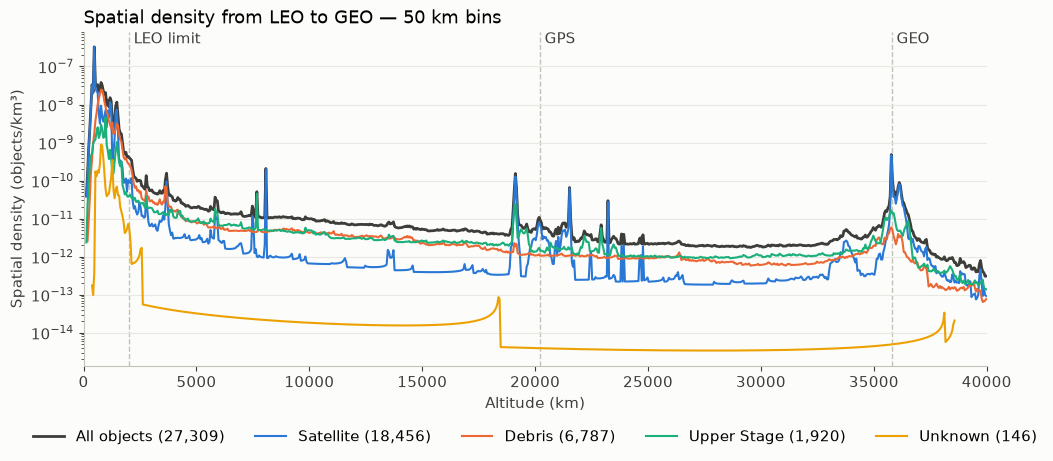

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.8))
prof = full["All objects"]
ax.plot(prof["altitude"], prof["density"].where(prof["density"] > 0), color="#3d3d3a",
        linewidth=2, label=f"All objects ({len(in_orbit):,})")
for obj_type in categories:
    label, color = TYPE_MAP[obj_type]
    prof = full[label]
    ax.plot(prof["altitude"], prof["density"].where(prof["density"] > 0), color=color,
            linewidth=1.5, label=f"{label} ({len(groups[label]):,})")
for alt, name in [(2000, "LEO limit"), (20200, "GPS"), (35786, "GEO")]:
    ax.axvline(alt, color="#c3c2b7", linewidth=1, linestyle="--", zorder=0)
    ax.text(alt, 1, f" {name}", transform=ax.get_xaxis_transform(), va="top", color="#3d3d3a")
ax.set_yscale("log")
ax.set_xlim(0, FULL_MAX)
ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Spatial density (objects/km³)")
ax.set_title(f"Spatial density from LEO to GEO — {FULL_BIN} km bins", loc="left")
ax.legend(frameon=False, loc="upper center", ncols=len(categories) + 1, bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
plt.show()